# iris-vector-graph: a walkthrough

What a graph database is, how iris-vector-graph (IVG) builds one on InterSystems IRIS, and the three parts opsreview
uses: Cypher, temporal edges and the ledger. Every cell runs against a live IRIS and prints what IRIS holds afterwards.

| Part | What it shows |
| ---- | ------------- |
| 1 | Nodes, labels, properties and relationships: a small opsreview-shaped graph |
| 2 | Asking it questions in Cypher, and the SQL the same question needs |
| 3 | How IVG stores the graph: four SQL tables, and the `^KG` adjacency global derived from them |
| 4 | How a query runs: the native executor over `^KG`, or the SQL path, and why the first is faster |
| 5 | Time: temporal edges, the event store pattern opsreview uses (window reads, buckets, retention) |
| 6 | The ledger: every governed write as a revision you can list, diff and verify |
| 7 | Vectors, briefly |
| 8 | Inside IRIS: the same graph from ObjectScript and from Embedded Python |
| 9 | A map of the code, for reading it next |

**Before running**

```bash
scripts/enterprise-container.sh up          # the ivg-iris-enterprise container (SQL port 31972)
.venv/bin/jupyter lab docs/notebooks/ivg_walkthrough.ipynb
```

The notebook uses the `IVGDEMO` namespace, which has its own database and its own copy of IVG's ObjectScript classes.
To make it on a fresh container, see `docs/notebooks/build_ivg_walkthrough.py` (the `IVGDEMO` recipe at the end of this
notebook). It erases `IVGDEMO`'s graph first, so it can be run again from the top.

In [1]:
import os, json, time, random, logging
import iris
import pandas as pd
from iris_vector_graph.engine import IRISGraphEngine

# IVG warns about two things that do not apply here: a namespace other than USER (IVGDEMO has its own ^KG), and the
# optional Rust accelerator (Arno), which this container does not load
logging.getLogger("iris_vector_graph").setLevel(logging.ERROR)

HOST = os.environ.get("IVG_HOST", "localhost")
PORT = int(os.environ.get("IVG_PORT", "31972"))
NAMESPACE = os.environ.get("IVG_NAMESPACE", "IVGDEMO")

conn = iris.connect(HOST, PORT, NAMESPACE, "_SYSTEM", "SYS")
engine = IRISGraphEngine(conn, embedding_dimension=8)
native = iris.createIRIS(conn)          # the Native API: globals and class methods, alongside SQL on the same connection
# a clean start, so the notebook can run again from the top: the ledger's history (part 6), then the graph
native.classMethodValue("Graph.KG.Ledger", "PurgeAll")
print("erased", engine.erase_all(), "rows from", NAMESPACE)

def q(cypher, **params):
    # Run a Cypher query and show its rows as a table.
    r = engine.execute_cypher(cypher, params)
    if r.error:
        raise RuntimeError(r.error)
    return pd.DataFrame(r.rows, columns=r.columns)

def sql(text, *args):
    cur = conn.cursor()
    cur.execute(text, list(args))
    cols = [d[0] for d in cur.description]
    return pd.DataFrame([list(row) for row in cur.fetchall()], columns=cols)

erased 269 rows from IVGDEMO


## 1. What is a graph database?

A graph database stores **things** and the **connections between them**, and treats the connections as data in their
own right.

- A **node** is a thing: a customer, an IRIS instance, a finding. Its **id** names it.
- A **label** says what kind of thing it is (`Customer`, `Instance`, `Finding`). A node can have several.
- **Properties** are its key/value facts (`version: "2025.1"`, `severity: "high"`).
- A **relationship** (an edge) connects two nodes. It has a **type** (`RUNS`, `ABOUT`) and a **direction**, and it can
  carry properties of its own.

```
(acme:Customer) -[:RUNS]-> (prod1:Instance) <-[:ABOUT]- (f1:Finding {severity: "high"})
                                  |
                              [:MIRRORS]
                                  v
                           (prod2:Instance)
```

Why bother, when a relational table can hold the same facts? Because the questions are about **paths**: "which
customers have an instance whose mirror partner has a high-severity finding?" In SQL every hop is another join, and you
write the joins yourself. In a graph database you draw the path, and the engine follows each node's connections
directly instead of searching a table for them.

Below is a small opsreview-shaped graph: two customers, their instances, the components on them, mirror partnerships,
and findings about the instances.

In [2]:
customers = {"acme": "Acme Health", "globex": "Globex Labs"}
instances = {  # id: (customer, version, role)
    "acme-prod-1": ("acme", "2025.1", "primary"),
    "acme-prod-2": ("acme", "2025.1", "backup"),
    "acme-test-1": ("acme", "2026.1", "test"),
    "globex-prod-1": ("globex", "2024.3", "primary"),
    "globex-prod-2": ("globex", "2024.3", "backup"),
    "acme-dr-1": ("acme", "2025.1", "disaster recovery"),
}
components = ["IRIS", "WebGateway", "Mirror", "Interoperability"]
findings = [  # (id, about, severity, title)
    ("f1", "acme-prod-1", "high", "Journal space below 10%"),
    ("f2", "acme-prod-1", "medium", "License use above 80%"),
    ("f3", "acme-prod-2", "high", "Mirror member behind by 40 s"),
    ("f4", "globex-prod-1", "low", "Old TLS cipher enabled"),
    ("f5", "globex-prod-2", "high", "Database expansion failed"),
]

for cid, name in customers.items():
    engine.create_node(f"customer:{cid}", labels=["Customer"], properties={"name": name})
for iid, (cid, version, role) in instances.items():
    engine.create_node(f"instance:{iid}", labels=["Instance"], properties={"name": iid, "version": version, "role": role})
    engine.create_edge(f"customer:{cid}", "RUNS", f"instance:{iid}")
for comp in components:
    engine.create_node(f"component:{comp}", labels=["Component"], properties={"name": comp})
for iid in instances:
    for comp in (components if "prod" in iid else components[:2]):
        engine.create_edge(f"instance:{iid}", "HAS_COMPONENT", f"component:{comp}")
engine.create_edge("instance:acme-prod-1", "MIRRORS", "instance:acme-prod-2")
engine.create_edge("instance:acme-prod-2", "MIRRORS", "instance:acme-dr-1")
engine.create_edge("instance:globex-prod-1", "MIRRORS", "instance:globex-prod-2")
for fid, about, severity, title in findings:
    engine.create_node(f"finding:{fid}", labels=["Finding"], properties={"severity": severity, "title": title})
    engine.create_edge(f"finding:{fid}", "ABOUT", f"instance:{about}")

q("MATCH (n) RETURN labels(n)[0] AS label, count(*) AS nodes ORDER BY label")

,label,nodes
0,Component,4
1,Customer,2
2,Finding,5
3,Instance,6


Reading the graph back and drawing it. Each edge is one relationship, coloured by its type.

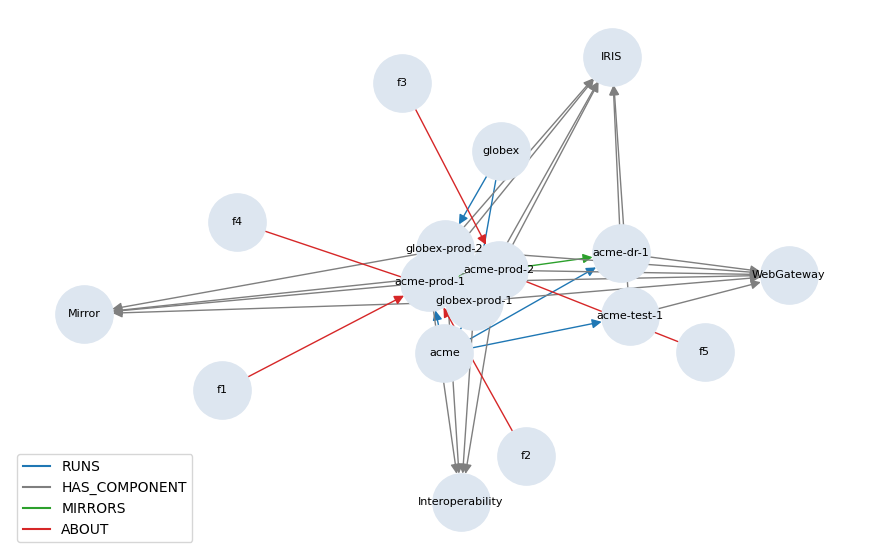

In [3]:
import networkx as nx
import matplotlib.pyplot as plt

edges = q("MATCH (a)-[r]->(b) RETURN a.node_id AS a, type(r) AS t, b.node_id AS b")
G = nx.DiGraph()
for a, t, b in edges.itertuples(index=False):
    G.add_edge(a.split(":", 1)[1], b.split(":", 1)[1], t=t)
colours = {"RUNS": "tab:blue", "HAS_COMPONENT": "tab:gray", "MIRRORS": "tab:green", "ABOUT": "tab:red"}
plt.figure(figsize=(11, 7))
pos = nx.spring_layout(G, seed=7, k=0.9)
nx.draw_networkx(G, pos, node_color="#dde6f0", node_size=1700, font_size=8,
                 edge_color=[colours[G.edges[e]["t"]] for e in G.edges], arrowsize=14)
plt.legend(handles=[plt.Line2D([0], [0], color=c, label=t) for t, c in colours.items()], loc="lower left")
plt.axis("off"); plt.show()

## 2. Asking questions in Cypher

Cypher describes the shape you are looking for with ASCII art: `(a)` is a node, `-[:TYPE]->` a relationship, and
`WHERE`, `RETURN`, `ORDER BY` work as in SQL. IVG speaks openCypher (it passes the openCypher TCK, 3,896 of 3,896
scenarios).

**One hop:** each customer and the instances it runs.

In [4]:
q("MATCH (c:Customer)-[:RUNS]->(i:Instance) RETURN c.name AS customer, i.name AS instance, i.role AS role "
  "ORDER BY customer, instance")

,customer,instance,role
0,Acme Health,acme-dr-1,disaster recovery
1,Acme Health,acme-prod-1,primary
2,Acme Health,acme-prod-2,backup
3,Acme Health,acme-test-1,test
4,Globex Labs,globex-prod-1,primary
5,Globex Labs,globex-prod-2,backup


**An aggregate:** findings per instance, worst first. Grouping is implicit: every non-aggregate in `RETURN` is a key.

In [5]:
q("MATCH (f:Finding)-[:ABOUT]->(i:Instance) "
  "RETURN i.name AS instance, count(f) AS findings, collect(f.severity) AS severities ORDER BY findings DESC, instance")

,instance,findings,severities
0,acme-prod-1,2,"[""high"",""medium""]"
1,acme-prod-2,1,"[""high""]"
2,globex-prod-1,1,"[""low""]"
3,globex-prod-2,1,"[""high""]"


**Two hops with a filter and a parameter:** the customers with a high-severity finding on any instance. `$severity` is
a parameter, passed separately like a SQL bind.

In [6]:
q("MATCH (c:Customer)-[:RUNS]->(i:Instance)<-[:ABOUT]-(f:Finding) WHERE f.severity = $severity "
  "RETURN c.name AS customer, i.name AS instance, f.title AS finding ORDER BY customer, instance",
  severity="high")

,customer,instance,finding
0,Acme Health,acme-prod-1,Journal space below 10%
1,Acme Health,acme-prod-2,Mirror member behind by 40 s
2,Globex Labs,globex-prod-2,Database expansion failed


**A path of any length:** which instances does a failure of `acme-prod-1` reach through mirror partnerships, and how
far? `*1..3` means one to three `MIRRORS` hops. In SQL this is a recursive CTE.

In [7]:
q("MATCH p = (a:Instance {name: $name})-[:MIRRORS*1..3]->(b:Instance) "
  "RETURN b.name AS reaches, length(p) AS hops ORDER BY hops", name="acme-prod-1")

,reaches,hops
0,acme-prod-2,1
1,acme-dr-1,2


**The same question in SQL.** IVG can answer most Cypher with SQL over its tables (part 3). With the native executor
turned off, the result carries the SQL it ran: one join per hop, plus the label and property tables for every filter.
This is the query you would otherwise write by hand.

In [8]:
engine.native_cypher = False
r = engine.execute_cypher(
    "MATCH (c:Customer)-[:RUNS]->(i:Instance)<-[:ABOUT]-(f:Finding) WHERE f.severity = 'high' "
    "RETURN c.name AS customer, count(f) AS high_findings")
engine.native_cypher = True
print(r.sql)
print(r.rows)

SELECT %EXACT(p9.val) AS customer, COUNT(n5.node_id) AS high_findings
FROM Graph_KG.nodes n0
JOIN Graph_KG.rdf_labels l1 ON l1.s = n0.node_id AND l1.label = ?
JOIN Graph_KG.rdf_edges e3 ON e3.s = n0.node_id AND e3.p = ?
JOIN Graph_KG.nodes n2 ON n2.node_id = e3.o_id
JOIN Graph_KG.rdf_labels l4 ON l4.s = n2.node_id AND l4.label = ?
JOIN Graph_KG.rdf_edges e6 ON e6.o_id = n2.node_id AND e6.p = ?
JOIN Graph_KG.nodes n5 ON n5.node_id = e6.s
JOIN Graph_KG.rdf_labels l7 ON l7.s = n5.node_id AND l7.label = ?
LEFT JOIN Graph_KG.rdf_props p8 ON p8.s = n5.node_id AND p8."key" = ?
LEFT JOIN Graph_KG.rdf_props p9 ON p9.s = n0.node_id AND p9."key" = ?
WHERE EXISTS (SELECT 1 FROM Graph_KG.rdf_props _sgn5 WHERE _sgn5.s = n5.node_id AND _sgn5."key" = 'severity') AND l1.s IS NOT NULL AND l4.s IS NOT NULL AND l7.s IS NOT NULL AND (p8.val = 'high' AND p8.val_key = 'high')
GROUP BY %EXACT(p9.val)
[['Acme Health', 2], ['Globex Labs', 1]]


## 3. How IVG stores a graph

IVG keeps the graph in **four ordinary SQL tables** in the `Graph_KG` schema. They are the source of truth: you can
query, back up and govern them as any other IRIS table.

| Table | One row per | Columns that matter |
| ----- | ----------- | ------------------- |
| `Graph_KG.nodes` | node | `node_id`, `graph_id` |
| `Graph_KG.rdf_labels` | label of a node | `s` (the node), `label` |
| `Graph_KG.rdf_props` | property of a node | `s`, `key`, `val` |
| `Graph_KG.rdf_edges` | relationship | `s` (source), `p` (type), `o_id` (target), `qualifiers` (its properties as JSON) |

The `rdf_` names come from RDF, where a fact is a triple (subject, predicate, object). `graph_id` lets one namespace
hold several named graphs; empty means the default graph. Here is `acme-prod-1` across the four tables:

In [9]:
node = "instance:acme-prod-1"
display(sql("SELECT node_id, graph_id FROM Graph_KG.nodes WHERE node_id = ?", node))
display(sql("SELECT s, label FROM Graph_KG.rdf_labels WHERE s = ?", node))
display(sql('SELECT s, "key", val FROM Graph_KG.rdf_props WHERE s = ?', node))
display(sql("SELECT s, p, o_id, qualifiers FROM Graph_KG.rdf_edges WHERE s = ? OR o_id = ? ORDER BY p", node, node))

,node_id,graph_id
0,instance:acme-prod-1,


,s,label
0,instance:acme-prod-1,Instance


,s,key,val
0,instance:acme-prod-1,name,acme-prod-1
1,instance:acme-prod-1,version,2025.1
2,instance:acme-prod-1,role,primary
3,instance:acme-prod-1,id,instance:acme-prod-1


,s,p,o_id,qualifiers
0,finding:f1,ABOUT,instance:acme-prod-1,None
1,finding:f2,ABOUT,instance:acme-prod-1,None
2,instance:acme-prod-1,HAS_COMPONENT,component:IRIS,None
3,instance:acme-prod-1,HAS_COMPONENT,component:WebGateway,None
4,instance:acme-prod-1,HAS_COMPONENT,component:Mirror,None
5,instance:acme-prod-1,HAS_COMPONENT,component:Interoperability,None
6,instance:acme-prod-1,MIRRORS,instance:acme-prod-2,None
7,customer:acme,RUNS,instance:acme-prod-1,None


### The adjacency global `^KG`

Tables answer "find the rows where s = X" through an index: a B-tree search for every hop. A graph engine wants
something more direct: from a node, its neighbours, immediately. IVG keeps that in an IRIS **global**, `^KG`: a sorted,
persistent, multi-dimensional array, the storage layer IRIS itself is built on.

```
^KG("out", graph, source, type, target) = weight      every outgoing edge
^KG("in",  graph, target, type, source) = weight      the same edge, from the other end
^KG("label", graph, label, node)        = ""          members of a label
```

Following an edge is reading the next subscript: `$Order` over `^KG("out", g, "instance:acme-prod-1", "MIRRORS", "")`
lists that node's mirror partners without touching a table. This is the "index-free adjacency" graph databases are
known for.

`^KG` is **derived from the tables**: a functional index on `rdf_edges` and `rdf_labels` updates it inside the same
transaction as every insert, update and delete, whether it comes from IVG, SQL or anything else. So it is never stale
and never needs a rebuild after ordinary writes.

Reading it with the Native API:

In [10]:
gkey = native.classMethodValue("Graph.KG.GraphKey", "ForIndex", "")   # the subscript for the default graph

def out_edges(node):
    rows = []
    for ptype, _ in native.iterator("KG", "out", gkey, node).items():
        for target, weight in native.iterator("KG", "out", gkey, node, ptype).items():
            rows.append((node, ptype, target, weight))
    return pd.DataFrame(rows, columns=["source", "type", "target", "weight"])

out_edges("instance:acme-prod-1")

,source,type,target,weight
0,instance:acme-prod-1,HAS_COMPONENT,component:IRIS,1.0
1,instance:acme-prod-1,HAS_COMPONENT,component:Interoperability,1.0
2,instance:acme-prod-1,HAS_COMPONENT,component:Mirror,1.0
3,instance:acme-prod-1,HAS_COMPONENT,component:WebGateway,1.0
4,instance:acme-prod-1,MIRRORS,instance:acme-prod-2,1.0


Writing a row moves `^KG` with it, and deleting it removes the entry. Neither call mentions `^KG`:

In [11]:
engine.create_edge("instance:acme-test-1", "MIRRORS", "instance:acme-prod-1")
print("after insert:", native.isDefined("KG", "out", gkey, "instance:acme-test-1", "MIRRORS", "instance:acme-prod-1") > 0)
cur = conn.cursor()
cur.execute("DELETE FROM Graph_KG.rdf_edges WHERE s = ? AND p = ?", ["instance:acme-test-1", "MIRRORS"])
conn.commit()
print("after a plain SQL DELETE:", native.isDefined("KG", "out", gkey, "instance:acme-test-1", "MIRRORS", "instance:acme-prod-1") > 0)

after insert: True
after a plain SQL DELETE: False


## 4. How a query runs: two engines

```
Cypher text
   |  iris_vector_graph/cypher/parser.py        -> an AST (ast.py)
   v
native_plan.py: can the native executor run it?
   |-- yes -> a JSON plan -> Graph.KG.Cypher.Exec (ObjectScript, inside IRIS) walks ^KG, reads properties, groups,
   |          sorts, applies LIMIT, and returns rows
   |-- no  -> translator.py -> SQL over the four tables -> IRIS SQL
```

- The **native executor** (`iris_src/src/Graph/KG/Cypher/Exec.cls`) answers the reads most applications ask: `MATCH`
  chains from an id or property lookup, fixed and variable-length hops, `WHERE` comparisons, `RETURN` with `DISTINCT`,
  `ORDER BY`, `LIMIT`, grouped counts. It runs next to the data, walking `^KG`, and splits big walks across worker
  processes.
- Everything else (writes, `OPTIONAL MATCH`, most functions, procedures) goes to the **SQL path**: `translator.py`
  turns the AST into SQL. Both paths name and type their answers with the same code, and shadow mode
  (`engine.cypher_shadow = True`) runs both and raises if they ever differ.

To see both paths answer, a slightly bigger synthetic graph: 300 instances, each with 1 to 4 findings and 2 to 4
network neighbours (a few seconds to load). It is far too small for the speed difference to matter; the benchmark
numbers below are for that.

In [12]:
random.seed(1)
N = 300
nodes = [{"id": f"syn:i{k}", "labels": ["SynInstance"], "properties": {"name": f"i{k}", "region": random.choice("ABCD")}}
         for k in range(N)]
edges = []
for k in range(N):
    for j in random.sample(range(N), random.randint(2, 4)):
        edges.append({"source_id": f"syn:i{k}", "predicate": "LINKS", "target_id": f"syn:i{j}"})
    for m in range(random.randint(1, 4)):
        fid = f"syn:f{k}_{m}"
        nodes.append({"id": fid, "labels": ["SynFinding"], "properties": {"severity": random.choice(["low", "medium", "high"])}})
        edges.append({"source_id": fid, "predicate": "ABOUT", "target_id": f"syn:i{k}"})
t = time.perf_counter()
# disable_indexes=False: the bulk loaders' default turns indexes off and rebuilds them whole, which pays only for
# loads of millions of rows
engine.bulk_create_nodes(nodes, disable_indexes=False)
engine.bulk_create_edges(edges, disable_indexes=False)
print(f"{len(nodes):,} nodes and {len(edges):,} edges in {time.perf_counter() - t:.1f} s")

1,049 nodes and 1,667 edges in 1.5 s


In [13]:
# for every instance: the high-severity findings two network hops away, counted by the starting instance's region
QUESTION = ("MATCH (a:SynInstance)-[:LINKS]->(b:SynInstance)-[:LINKS]->(c:SynInstance)<-[:ABOUT]-(f:SynFinding) "
            "WHERE f.severity = 'high' RETURN a.region AS region, count(*) AS paths ORDER BY region")

def timed(native_on, runs=5):
    engine.native_cypher = native_on
    best = float("inf")
    for _ in range(runs):
        t = time.perf_counter(); r = engine.execute_cypher(QUESTION); best = min(best, time.perf_counter() - t)
    engine.native_cypher = True
    return best * 1000, r.rows

native_ms, native_rows = timed(True)
sql_ms, sql_rows = timed(False)
print(f"native executor {native_ms:6.1f} ms   SQL path {sql_ms:6.1f} ms   same answer: {sorted(native_rows) == sorted(sql_rows)}")
pd.DataFrame(native_rows, columns=["region", "paths"])

native executor   23.1 ms   SQL path   29.3 ms   same answer: True


,region,paths
0,A,645
1,B,568
2,C,642
3,D,664


Both paths give the same answer; the native one reads `^KG` instead of joining tables, and on a graph this small
both take a few milliseconds. The gap opens with size: on the LDBC Social Network Benchmark at scale factor 1 (3.7 M nodes, 21 M edges, 40 queries) the native path's median time is 1.2x Neo4j's and
0.9x Memgraph's; see `docs/performance/alt-bench/REPORT_TEMPLATE.md`.

## 5. Time: temporal edges

opsreview records **events**: an action on an instance, a configuration change, a metric sample. IVG stores these as
**temporal edges**: an edge with a timestamp, `(ts, source, type, target)`. Many edges can join the same two nodes at
different times.

The pattern opsreview uses: each event is its own node, with an id taken from its `event_id`, and the edge is
`(ts, instance, ACTION_AT, action:<event_id>)`. A replay rewrites the same edge; two events in the same millisecond
cannot collide; the event's details are the edge's attributes.

The temporal store is a set of globals, kept by `Graph.KG.TemporalIndex`:

```
^KG("tout", graph, ts, source, type, target) = weight     by time, then source
^KG("tin",  graph, ts, target, type, source) = weight     by time, then target
^KG("bucket", ...), ^KG("tagg", ...)                      per-bucket counts, sums and distinct counts (pre-aggregated)
^KG("tlast", graph, source, type) = ts                    each source's newest event
```

Two days of actions on three instances, one an hour:

In [14]:
T0 = 1_760_000_000            # a fixed start (seconds) so the output is the same every run
HOUR = 3600
kinds = ["backup", "restart", "config_change", "license_check"]
events, eid = [], 0
for iid in ["acme-prod-1", "acme-prod-2", "globex-prod-1"]:
    for step in range(0, 48 * HOUR, HOUR):
        eid += 1
        events.append({"s": f"instance:{iid}", "p": "ACTION_AT", "o": f"action:{eid}", "ts": T0 + step,
                       "w": random.randint(1, 100), "attrs": {"kind": random.choice(kinds), "event_id": str(eid)}})
written = engine.bulk_create_edges_temporal(events)
print(f"written {int(written):,}  collisions {written.collisions}")

# writing the same coordinates again in mode "insert" changes nothing, and says so (spec 254)
again = engine.bulk_create_edges_temporal(events[:10], mode="insert")
print(f"replayed 10: written {int(again)}  collisions {again.collisions}")

written 144  collisions 0
replayed 10: written 0  collisions 10


**A window:** one instance's actions in a 2-hour window, each with its attributes, read page by page from the server.

In [15]:
cur_w = engine.iter_edges_in_window(T0 + 24 * HOUR, T0 + 26 * HOUR, source="instance:acme-prod-1", predicates=["ACTION_AT"])
pd.DataFrame([{"ts": e["ts"], "target": e["target"], **(e.get("attrs") or {})} for e in cur_w]).head(8)

,ts,target,event_id,kind
0,1760086400,action:25,25,license_check
1,1760090000,action:26,26,config_change
2,1760093600,action:27,27,restart


**Buckets:** counts and sums per source over a range, from the pre-aggregated buckets (no raw edge is read), and the
newest event per instance:

In [16]:
display(pd.DataFrame(engine.get_bucket_groups("ACTION_AT", T0, T0 + 48 * HOUR, source_prefix="instance:")))
pd.DataFrame(engine.get_latest_edges(source_prefix="instance:", predicate="ACTION_AT"))[["source", "target", "timestamp", "attrs"]]

,source,predicate,count,sum,avg,min,max
0,instance:acme-prod-1,ACTION_AT,48,2379,49.562500,1,97
1,instance:acme-prod-2,ACTION_AT,48,2315,48.229167,3,100
2,instance:globex-prod-1,ACTION_AT,48,2449,51.020833,1,100


,source,target,timestamp,attrs
0,instance:acme-prod-1,action:48,1760169200,"{'event_id': '48', 'kind': 'restart'}"
1,instance:acme-prod-2,action:96,1760169200,"{'event_id': '96', 'kind': 'backup'}"
2,instance:globex-prod-1,action:144,1760169200,"{'event_id': '144', 'kind': 'backup'}"


**Retention.** opsreview keeps 48 hours of raw events; here, everything older than the first 24 hours goes. `purge_raw_before` removes every raw edge older than a cutoff,
and (spec 254) the structural row and `^KG("out")` entry each one held up, so one-node-per-event adjacency does not grow
forever. The buckets stay.

In [17]:
def counts():
    return {"raw edges": sum(1 for _ in engine.iter_edges_in_window(T0, T0 + 49 * HOUR, source_prefix="instance:", attrs=False)),
            "rdf_edges rows": int(sql("SELECT COUNT(*) AS n FROM Graph_KG.rdf_edges WHERE p = 'ACTION_AT'")["n"][0])}

print("before:", counts())
res = engine.purge_raw_before(T0 + 24 * HOUR)
print("purged:", res.deleted, "edges")
print("after: ", counts())

before: {'raw edges': 144, 'rdf_edges rows': 144}
purged: 72 edges
after:  {'raw edges': 72, 'rdf_edges rows': 72}


## 6. The ledger: governed writes

The ledger records writes as **revisions**: who made them (`actor`), why (`message`), and exactly what changed. You can
list them, look one up, and diff two of them. opsreview uses it for
writes that must be auditable.

Enabling the ledger snapshots the graph as its first revision ("genesis"). The synthetic graph from part 4 goes first,
so the ledger starts from the small opsreview graph. A write then goes through a **changeset**, committed as one
revision:

In [18]:
from iris_vector_graph.ledger import Changeset

engine.delete_nodes_by_prefix("syn:")
engine.ledger.enable()
cs = Changeset(actor="luca", actor_type="human", message="record a new finding on acme-prod-2")
cs.create_node("finding:f6", labels=["Finding"], properties={"severity": "medium", "title": "CSP gateway timeout"})
cs.create_relationship("finding:f6", "ABOUT", "instance:acme-prod-2")
first = engine.ledger.commit(cs)

cs2 = Changeset(actor="luca", actor_type="human", message="raise it to high")
cs2.set_property("finding:f6", "severity", "high")
second = engine.ledger.commit(cs2)

page = engine.ledger.history(descending=True, limit=5)
pd.DataFrame([{"revision": r.revision_id[:12], "actor": r.actor, "message": r.message, "ops": r.op_count} for r in page.revisions])

,revision,actor,message,ops
0,dcd78700ce1c,luca,raise it to high,1
1,dcd717fdce1c,luca,record a new finding on acme-prod-2,5
2,dcc4eea6ce1c,system:ledger,genesis,461


In [19]:
print(engine.ledger.diff(first.revision.revision_id, second.revision.revision_id))
q("MATCH (f:Finding {node_id: 'finding:f6'})-[:ABOUT]->(i) RETURN f.title AS title, f.severity AS severity, i.name AS instance")

Diff(entries=[DiffEntry(entity_kind='node', entity_id='finding:f6', attr='prop:severity', before='medium', after='high')], redacted=[])


,title,severity,instance
0,CSP gateway timeout,high,acme-prod-2


## 7. Vectors, briefly

The "vector" in the name: a node can carry an embedding, and IVG combines vector similarity with the graph (search by
meaning, then walk the neighbours). Toy 8-dimensional vectors here; real ones come from an embedding model.

In [20]:
import math
def toy_vector(text):
    v = [0.0] * 8
    for i, ch in enumerate(text.lower()):
        v[(ord(ch) + i) % 8] += 1.0
    n = math.sqrt(sum(x * x for x in v)) or 1.0
    return [x / n for x in v]

for fid, _about, _sev, title in findings:
    engine.store_embedding(f"finding:{fid}", toy_vector(title))
hits = engine.kg_KNN_VEC(json.dumps(toy_vector("journal disk space")), k=3)
pd.DataFrame(hits, columns=["node", "score"])

,node,score
0,finding:f5,0.884452
1,finding:f3,0.882005
2,finding:f1,0.791353


## 8. Inside IRIS: ObjectScript and Embedded Python

Everything so far ran in this notebook's Python, over a network connection. The same graph is usable from code that
runs **inside** IRIS: an ObjectScript class in a production, a business process, a REST handler, or a
`[ Language = python ]` method. Nothing is copied out: ObjectScript and Embedded Python read the same tables and the same
`^KG` global, in the same process.

| From | How |
| ---- | --- |
| ObjectScript, Cypher | `##class(IVG.CypherEngine).Local().Query(cypher, paramsJSON)`: IVG's engine run in-process; a `%DynamicObject` back |
| ObjectScript, direct | `$Order(^KG("out", graph, node, type, ...))`, `##class(Graph.KG.Adj).Degree(...)`, `##class(Graph.KG.TemporalIndex).InsertEdge(...)` / `.QueryWindow(...)` |
| ObjectScript, SQL | `%SQL.Statement` over the `Graph_KG` tables |
| Embedded Python, `iris` module | `iris.gref("^KG")`, `iris.cls("Graph.KG.Adj")`, `iris.sql.exec(...)` |
| Embedded Python, IVG's engine | `IRISGraphEngine(EmbeddedConnection(iris.sql))`: the API of parts 1 to 7, with no network |

`docs/notebooks/objectscript/IVGDemo.Walkthrough.cls` has one method per row. The next cell loads and compiles it into
`IVGDEMO` over this notebook's connection and prints its source.

In [21]:
from pathlib import Path
from IPython.display import Markdown

CLS = Path("docs/notebooks/objectscript/IVGDemo.Walkthrough.cls")
if not CLS.exists():                      # run from docs/notebooks rather than the repo root
    CLS = Path("objectscript/IVGDemo.Walkthrough.cls")
source = CLS.read_text()

# write the source to a file on the IRIS server, then load and compile it there
dest = "/tmp/ivgdemo_src/IVGDemo.Walkthrough.cls"
native.classMethodValue("%File", "CreateDirectoryChain", "/tmp/ivgdemo_src")
stream = native.classMethodObject("%Stream.FileCharacter", "%New")
stream.invokeVoid("LinkToFile", dest)
for line in source.split("\n"):
    stream.invokeVoid("WriteLine", line)
stream.invokeVoid("%Save")
status = native.classMethodValue("%SYSTEM.OBJ", "Load", dest, "ck-d")
assert native.classMethodValue("%SYSTEM.Status", "IsOK", status), native.classMethodValue("%SYSTEM.Status", "GetOneErrorText", status)

def call(method, *args):
    # Call a class method of IVGDemo.Walkthrough in IRIS and parse the JSON it returns.
    value = native.classMethodValue("IVGDemo.Walkthrough", method, *args)
    try:
        return json.loads(value)
    except (TypeError, ValueError):
        return value

Markdown(f"```objectscript\n{source}\n```")

```objectscript
/// Calling iris-vector-graph from code that runs inside IRIS: ObjectScript and Embedded Python.
/// Loaded and called by docs/notebooks/ivg_walkthrough.ipynb (part 9) in the IVGDEMO namespace.
Class IVGDemo.Walkthrough Extends %RegisteredObject
{

/// Cypher from ObjectScript: IVG.CypherEngine runs IVG's Python engine inside this process, on this namespace.
/// The result is a %DynamicObject {columns, rows, error}.
ClassMethod CypherFromObjectScript(pSeverity As %String = "high") As %String
{
	Set tEngine = ##class(IVG.CypherEngine).Local(8)
	Set tParams = {"severity": (pSeverity)}
	Set tResult = tEngine.Query("MATCH (f:Finding)-[:ABOUT]->(i:Instance) WHERE f.severity = $severity RETURN i.name AS instance, count(f) AS findings ORDER BY findings DESC, instance", tParams.%ToJSON())
	Quit tResult.%ToJSON()
}

/// The adjacency global directly: a node's neighbours over one relationship type are the subscripts under
/// ^KG("out", graph, node, type). No SQL, no Cypher: one $Order per neighbour.
ClassMethod Neighbours(pNode As %String, pType As %String) As %String
{
	Set tKey = ##class(Graph.KG.GraphKey).ForIndex(""), tOut = [], tTarget = ""
	For {
		Set tTarget = $Order(^KG("out", tKey, pNode, pType, tTarget))
		Quit:tTarget=""
		Do tOut.%Push(tTarget)
	}
	Quit tOut.%ToJSON()
}

/// A node's degree from IVG's server-side API (all relationship types when pType is "").
ClassMethod Degree(pNode As %String, pType As %String = "") As %Integer
{
	Quit ##class(Graph.KG.Adj).Degree(##class(Graph.KG.GraphKey).ForIndex(""), pNode, pType)
}

/// Record an event as opsreview does, one node per event: (ts, instance, ACTION_AT, action:<event id>), the details as
/// the edge's attributes. Then read the instance's window back.
ClassMethod RecordAndRead(pInstance As %String, pEventId As %String, pTs As %Integer, pKind As %String) As %String
{
	Set tSC = ##class(Graph.KG.TemporalIndex).InsertEdge("", pInstance, "ACTION_AT", "action:"_pEventId, pTs, 1, {"kind": (pKind), "event_id": (pEventId)}.%ToJSON())
	$$$ThrowOnError(tSC)
	Quit ##class(Graph.KG.TemporalIndex).QueryWindow("", pInstance, "ACTION_AT", pTs - 3600, pTs)
}

/// The graph's tables are ordinary SQL tables: findings per severity, from ObjectScript's dynamic SQL.
ClassMethod SeverityCounts() As %String
{
	Set tOut = {}
	Set tRS = ##class(%SQL.Statement).%ExecDirect(, "SELECT p.val, COUNT(*) FROM Graph_KG.rdf_labels l JOIN Graph_KG.rdf_props p ON p.s = l.s AND p.""key"" = 'severity' WHERE l.label = 'Finding' GROUP BY p.val")
	While tRS.%Next() {
		Do tOut.%Set(tRS.%GetData(1), tRS.%GetData(2))
	}
	Quit tOut.%ToJSON()
}

/// Embedded Python with the iris module: the same global, a class method and SQL, from Python running in IRIS.
ClassMethod NeighboursPy(pNode As %String, pType As %String) As %String [ Language = python ]
{
	import iris, json
	key = iris.cls("Graph.KG.GraphKey").ForIndex("")
	kg = iris.gref("^KG")
	targets, t = [], kg.order(["out", key, pNode, pType, ""])
	while t:
		targets.append(t)
		t = kg.order(["out", key, pNode, pType, t])
	degree = iris.cls("Graph.KG.Adj").Degree(key, pNode, "")
	rows = iris.sql.exec("SELECT COUNT(*) FROM Graph_KG.rdf_edges WHERE o_id = ? AND p = 'ABOUT'", pNode)
	about = next(iter(rows))[0]
	return json.dumps({"neighbours": targets, "degree": degree, "findings_about_it": about})
}

/// Embedded Python running IVG's own Python engine in-process, on an embedded connection: the same API as
/// IRISGraphEngine over a network connection, with no network.
ClassMethod CypherPy(pName As %String) As %String [ Language = python ]
{
	import json
	import iris
	from iris_vector_graph.embedded import EmbeddedConnection
	from iris_vector_graph.engine import IRISGraphEngine
	engine = IRISGraphEngine(EmbeddedConnection(iris.sql), embedding_dimension=8)
	r = engine.execute_cypher(
		"MATCH p = (a:Instance {name: $name})-[:MIRRORS*1..3]->(b:Instance) RETURN b.name AS reaches, length(p) AS hops ORDER BY hops",
		{"name": pName})
	return json.dumps({"columns": r.columns, "rows": r.rows, "error": r.error})
}

}

```

**Cypher from ObjectScript** (`CypherFromObjectScript`): the high-severity findings per instance, the question of
part 2, asked from an ObjectScript method. The first call in a process loads Python and the engine (about half a
second); later calls reuse them.

In [22]:
call("CypherFromObjectScript", "high")

{'columns': ['instance', 'findings'],
 'rows': [['acme-prod-2', 2], ['acme-prod-1', 1], ['globex-prod-2', 1]],
 'error': ''}

**The global directly** (`Neighbours`, `Degree`): `acme-prod-1`'s mirror partners by `$Order` over `^KG`, and its degree
from `Graph.KG.Adj` (every relationship out of it, its `ACTION_AT` events included).

In [23]:
print("mirror partners:", call("Neighbours", "instance:acme-prod-1", "MIRRORS"))
print("degree:", call("Degree", "instance:acme-prod-1"))

mirror partners: ['instance:acme-prod-2']
degree: 29


**A temporal write from ObjectScript** (`RecordAndRead`): one more event for `acme-prod-1`, through
`Graph.KG.TemporalIndex.InsertEdge`, then the last hour of its events with `QueryWindow`. The event's edge also asserts
its structural row, so the degree goes up by one.

In [24]:
latest = T0 + 47 * HOUR                     # the last hour of part 5's events
display(pd.DataFrame(call("RecordAndRead", "instance:acme-prod-1", "9001", latest, "restart")))
print("degree now:", call("Degree", "instance:acme-prod-1"))

,s,p,o,ts,w
0,instance:acme-prod-1,ACTION_AT,action:47,1760165600,43
1,instance:acme-prod-1,ACTION_AT,action:48,1760169200,77
2,instance:acme-prod-1,ACTION_AT,action:9001,1760169200,1


degree now: 30


**SQL from ObjectScript** (`SeverityCounts`): the tables are ordinary SQL tables, so `%SQL.Statement` reads them as it
would any other.

In [25]:
call("SeverityCounts")

{'high': 4, 'low': 1, 'medium': 1}

**Embedded Python** (`NeighboursPy`, `CypherPy`): the same reads in Python running inside IRIS. `NeighboursPy` uses the
`iris` module (a global reference, a class method, SQL). `CypherPy` runs IVG's own engine in-process over an embedded
connection, so the API from the rest of this notebook is available to Python inside IRIS with no network in between.

In [26]:
print(call("NeighboursPy", "instance:acme-prod-1", "MIRRORS"))
print(call("CypherPy", "acme-prod-1"))

{'neighbours': ['instance:acme-prod-2'], 'degree': 30, 'findings_about_it': 2}


{'columns': ['reaches', 'hops'], 'rows': [['acme-prod-2', 1], ['acme-dr-1', 2]], 'error': None}


For `CypherPy`, the container's Embedded Python (`/usr/irissys/mgr/python`) needs the `iris_vector_graph` package. On
`ivg-iris-enterprise` it was copied there from this checkout (2026-10-22); copy it again after changing the package.

## 9. A map of the code

| Where | What it is | Read it for |
| ----- | ---------- | ----------- |
| `iris_vector_graph/engine.py` | `IRISGraphEngine`, the one class callers use | the public API; each method delegates to a mixin |
| `iris_vector_graph/_engine/nodes_edges.py` | node and edge writes, bulk loads, deletes | how a write reaches the four tables |
| `iris_vector_graph/_engine/temporal.py` | temporal edges, windows, buckets, purge | opsreview's event store |
| `iris_vector_graph/_engine/ledger.py`, `iris_vector_graph/ledger/` | the ledger: changesets, revisions, verify | governed writes |
| `iris_vector_graph/_engine/query.py` | `execute_cypher`: routing between the native and SQL paths | what runs a query |
| `iris_vector_graph/cypher/parser.py`, `ast.py` | Cypher text to an AST | the language |
| `iris_vector_graph/cypher/native_plan.py` | AST to a native plan, or "not supported" | what the native path accepts |
| `iris_vector_graph/cypher/translator.py` | AST to SQL (large: the whole of openCypher) | the SQL path |
| `iris_vector_graph/_engine/schema.py` | DDL, indexes, deploying the ObjectScript classes | installing IVG |
| `iris_src/src/Graph/KG/Cypher/Exec.cls` | the native executor | how a walk over `^KG` answers a query |
| `iris_src/src/Graph/KG/Adjacency.cls`, `Adj.cls` | `^KG("out"/"in")` maintenance and reads | the adjacency global |
| `iris_src/src/Graph/KG/TemporalIndex.cls`, `TemporalWindow.cls` | the temporal globals | the event store, server side |
| `iris_src/src/Graph/KG/VarLength.cls` | variable-length walks (`*1..3`) | paths |
| `docs/adr/` | architecture decisions (ADR-0008/0009: `^KG` derived from the rows) | why it is built this way |
| `CONTEXT.md` | the project's glossary | the vocabulary |
| `tests/e2e/` | end-to-end tests against IRIS | worked examples of every feature |

**Suggested reading order:** `CONTEXT.md`, then `engine.py` (the API), `_engine/temporal.py` (what opsreview calls),
`_engine/query.py` (how a query is routed), and `Exec.cls` once the `^KG` layout in part 3 makes sense.

## The `IVGDEMO` namespace

Made once on `ivg-iris-enterprise` (2026-10-22). On a fresh container: in `%SYS`, create a database directory with
`SYS.Database`, then `Config.Databases.Create("IVGDEMO", ...)` and `Config.Namespaces.Create("IVGDEMO", ...)` with
`Globals` and `Routines` set to `IVGDEMO`. Then run `IRISGraphEngine(conn, embedding_dimension=8).initialize_schema()`
connected to `IVGDEMO`, and
`IVG_PORT=31972 IVG_NAMESPACE=IVGDEMO scripts/enterprise-container.sh tcp-deploy`.